# 交差検証 — 1 回の分割はどれだけ揺れるか、分け方を間違えると何が起きるか

**出典**　機械学習 4 分野の教科書 — 第 4 章 1-C アンサンブルと評価 ／ 04 交差検証

**このノートのパス**　`ml-code/04_ensemble_eval/05_cross_validation.ipynb`

**このノートで確かめること**

1. 1 回だけの hold-out 分割は、**分け方の乱数だけで**スコアがどれだけ動くか。5 分割交差検証ならどうか
2. `KFold` と `StratifiedKFold` で、検証 fold のクラス比がどう違うか
3. 同一ユーザーの行が複数あるデータで `KFold` を使うと、スコアがどれだけ楽観的になるか（`GroupKFold` との比較）
4. 時系列データで行をシャッフルして分割すると何が起きるか（`TimeSeriesSplit` との比較）

| 項目 | 内容 |
|---|---|
| 必要なパッケージ | `numpy`, `scikit-learn`, `matplotlib` |
| 実行時間の目安 | 約 20 秒 |
| 前提 | **このノート単体で完結する**（他のノートを先に実行する必要はない） |

In [1]:
# 未導入なら実行する（Colab など）
# !pip install -q numpy scikit-learn matplotlib

## ① hold-out 1 回 vs 5 分割交差検証

300 件・陽性 20% の小さな分類データで、同じモデルを評価する。
「分け方の乱数」だけを 100 通り変えて、スコアの散らばりを比べる。

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import (KFold, StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = make_classification(n_samples=300, n_features=20, n_informative=5,
                           weights=[0.8, 0.2], random_state=0)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

# 1 回だけ分ける（hold-out）を、分け方の乱数だけ変えて 100 回
holdout = []
for seed in range(100):
    X_tr, X_va, y_tr, y_va = train_test_split(X, y, test_size=0.2, stratify=y,
                                              random_state=seed)
    model.fit(X_tr, y_tr)
    holdout.append(roc_auc_score(y_va, model.predict_proba(X_va)[:, 1]))
holdout = np.array(holdout)

# 5 分割交差検証の「平均」を、分割の乱数だけ変えて 100 回
cv_means = np.array([
    cross_val_score(model, X, y, scoring="roc_auc",
                    cv=StratifiedKFold(5, shuffle=True, random_state=s)).mean()
    for s in range(100)
])

for name, s in [("hold-out 1 回", holdout), ("5-fold CV の平均", cv_means)]:
    print(f"{name:<14}: 最小 {s.min():.3f}  最大 {s.max():.3f}  標準偏差 {s.std():.3f}")

scores = cross_val_score(model, X, y, scoring="roc_auc",
                         cv=StratifiedKFold(5, shuffle=True, random_state=0))
print("\n1 回の 5-fold CV:", scores.round(3), f"→ {scores.mean():.3f} ± {scores.std():.3f}")

# 検証 fold の陽性率：KFold は偶然で偏り、StratifiedKFold は揃う
for name, splitter in [("KFold", KFold(5, shuffle=True, random_state=0)),
                       ("StratifiedKFold", StratifiedKFold(5, shuffle=True, random_state=0))]:
    rates = [y[va].mean() for _, va in splitter.split(X, y)]
    print(f"{name:>15}: 検証 fold の陽性率 {np.round(rates, 3)}")

hold-out 1 回  : 最小 0.715  最大 0.970  標準偏差 0.056
5-fold CV の平均 : 最小 0.830  最大 0.884  標準偏差 0.010

1 回の 5-fold CV: [0.863 0.828 0.875 0.859 0.908] → 0.867 ± 0.026
          KFold: 検証 fold の陽性率 [0.2   0.2   0.233 0.217 0.15 ]
StratifiedKFold: 検証 fold の陽性率 [0.2 0.2 0.2 0.2 0.2]


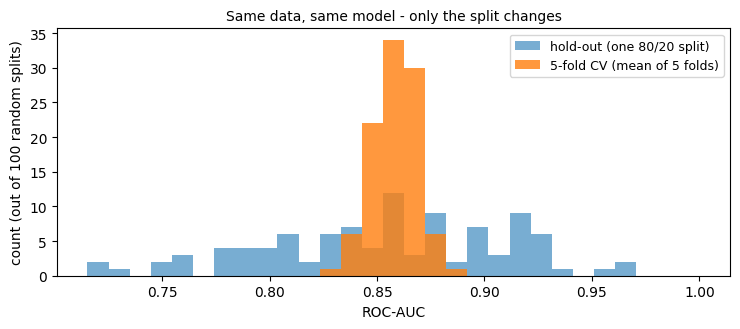

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
bins = np.linspace(min(holdout.min(), cv_means.min()), 1.0, 30)
ax.hist(holdout, bins=bins, alpha=0.6, label="hold-out (one 80/20 split)")
ax.hist(cv_means, bins=bins, alpha=0.8, label="5-fold CV (mean of 5 folds)")
ax.set_xlabel("ROC-AUC"); ax.set_ylabel("count (out of 100 random splits)")
ax.set_title("Same data, same model - only the split changes", fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## ② 分け方を間違えると、スコアは嘘になる

**グループ**：80 人のユーザーがそれぞれ 10 行ずつ持つデータ。同じユーザーの行は特徴量がよく似ていて、ラベルもユーザー単位で決まる。
`KFold` だと同じユーザーの行が訓練と検証の両方に入り、モデルは「このユーザーの答え」を覚えるだけで高得点を取れる。
**本番で知りたいのは新しいユーザーでの性能**なので、実際に新しい 80 人を作って答え合わせもする。

**時系列**：ランダムウォークする売上を、時刻から予測する。シャッフルした `KFold` では前後の時刻が訓練に入るので「内挿」で当たってしまう。

In [4]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import GroupKFold, TimeSeriesSplit

rng = np.random.default_rng(0)

def make_users(n_users, per_user=10):
    vec = rng.normal(size=(n_users, 8))                             # ユーザーごとの「癖」
    label = (vec[:, 0] + rng.normal(scale=1.5, size=n_users) > 0).astype(int)
    g = np.repeat(np.arange(n_users), per_user)
    X = vec[g] + rng.normal(scale=0.3, size=(len(g), 8))            # 同じ人の行はよく似る
    return X, label[g], g

Xg, yg, groups = make_users(80)
X_new, y_new, _ = make_users(80)                                    # 本番で来る「新しいユーザー」
rf = RandomForestClassifier(n_estimators=200, random_state=0)

print("【グループ】ROC-AUC")
for name, splitter, g in [("KFold", KFold(5, shuffle=True, random_state=0), None),
                          ("GroupKFold", GroupKFold(5), groups)]:   # GroupKFold だけに groups を渡す
    s = cross_val_score(rf, Xg, yg, groups=g, cv=splitter, scoring="roc_auc")
    print(f"  {name:<11} CV: {s.mean():.3f} ± {s.std():.3f}")
rf.fit(Xg, yg)
print(f"  新しいユーザー 80 人での実測: {roc_auc_score(y_new, rf.predict_proba(X_new)[:, 1]):.3f}")

# 時系列：600 日分のランダムウォークを、日付（通し番号）から予測する
t = np.arange(600).reshape(-1, 1)
sales = np.cumsum(rng.normal(size=600))
rfr = RandomForestRegressor(n_estimators=200, random_state=0)
print("\n【時系列】R²")
for name, splitter in [("KFold（シャッフル）", KFold(5, shuffle=True, random_state=0)),
                       ("TimeSeriesSplit", TimeSeriesSplit(5))]:
    s = cross_val_score(rfr, t, sales, cv=splitter, scoring="r2")
    print(f"  {name:<15} CV: {s.mean():+.3f}")

【グループ】ROC-AUC


  KFold       CV: 0.990 ± 0.004


  GroupKFold  CV: 0.721 ± 0.075
  新しいユーザー 80 人での実測: 0.685

【時系列】R²


  KFold（シャッフル）    CV: +0.996


  TimeSeriesSplit CV: -2.829


## 読み取りどころ

- **hold-out 1 回のスコアは、分け方の運だけで大きく動く。**「前回より 0.02 上がった」がノイズの範囲かどうか、1 回の分割では判断できない。
- **5 分割の平均は、同じデータでも散らばりが数分の一になる。**報告するときは平均と標準偏差をセットにする。
- **`StratifiedKFold` は検証 fold の陽性率をそろえる。**陽性が少ないほど、`KFold` の偏りが fold ごとのスコアを揺らす。分類では原則こちらを使う。
- **グループと時系列は、分け方を間違えるとスコアそのものが嘘になる。**`KFold` の高得点は、新しいユーザーや未来の日付では再現しない。`GroupKFold` / `TimeSeriesSplit` のほうが本番の実測に近い。